# Q1 - LIME

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torchvision.transforms as transforms
from torchvision.models import resnet18
from sklearn.linear_model import Lasso

def load_image(path):
    img = Image.open(path).convert('RGB')
    return img.resize((224, 224))

def kmeans_numpy(X, n_clusters, max_iter=100, tol=1e-4):
    n = X.shape[0]
    # Randomly choose initial centroids from the data
    idx = np.random.choice(n, size=n_clusters, replace=False)
    centroids = X[idx].copy()
    labels = np.zeros(n, dtype=np.int32)
    for it in range(max_iter):
        # Assign each point to nearest centroid
        dists = np.linalg.norm(X[:, None] - centroids[None], axis=2)  # (n, k)
        new_labels = np.argmin(dists, axis=1)
        # Update centroids
        new_centroids = np.array([X[new_labels == j].mean(axis=0) 
                                  for j in range(n_clusters)])
        # If a cluster is empty, re‑initialize its centroid randomly
        for j in range(n_clusters):
            if not np.any(new_labels == j):
                new_centroids[j] = X[np.random.choice(n)]
        # Check convergence
        if np.allclose(centroids, new_centroids, atol=tol):
            labels = new_labels
            centroids = new_centroids
            break
        centroids = new_centroids
        labels = new_labels
    return centroids, labels


def kmeans_segments(image_uint8, n_segments=64, max_iter=50):
    H, W = image_uint8.shape[:2]
    xs, ys = np.meshgrid(np.arange(W), np.arange(H))
    features = np.column_stack([
        image_uint8.reshape(-1, 3).astype(float),
        ys.ravel().astype(float) * (255.0 / H) ,
        xs.ravel().astype(float) * (255.0 / W)
    ])
    centroids, labels = kmeans_numpy(features, n_segments, 
                                     max_iter=max_iter)
    return labels.reshape(H, W)

In [2]:
MODEL_PATH = "resnet18-f37072fd.pth"    
np.random.seed(42)          
torch.manual_seed(42)      

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Using device:", device)

# Load model architecture and weights
model = resnet18(weights=None)   
state_dict = torch.load(MODEL_PATH, map_location=device)
model.load_state_dict(state_dict)
model.to(device)
model.eval()
print("Model loaded from", MODEL_PATH)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


Using device: cuda
Model loaded from resnet18-f37072fd.pth


C:\Users\Amin\AppData\Local\Temp\ipykernel_32552\3582346007.py:11: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(MODEL_PATH, map_location=device)


### Part 1 - Init Model

In [8]:
import torch.nn.functional as F
IMAGE_PATH = "cat.jpg"
img = load_image(IMAGE_PATH)
x = transform(img).unsqueeze(0).to(device)
with torch.no_grad():
    logits = model(x)
    probs = F.softmax(logits, dim=1)

cat_prob = probs[0, 282].item()
pred_prob, pred_class = torch.max(probs, dim=1)
print(f"Predicted class index: {pred_class.item()}")
print(f"Predicted class probability: {pred_prob.item()*100:.2f}%")

Predicted class index: 282
Predicted class probability: 90.55%


### Part 2 - Image Segmentation

Number of segments: 18


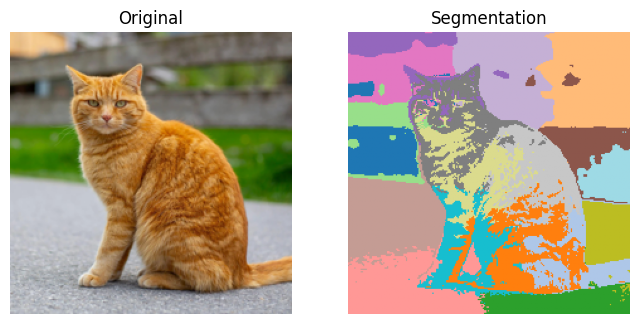

In [13]:
img_np = np.array(img)
segments = kmeans_segments(img_np, n_segments=18)
print("Number of segments:", len(np.unique(segments)))
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(img_np)
plt.title("Original")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(segments, cmap="tab20")
plt.title("Segmentation")
plt.axis("off")
plt.show()

### Part 3 - Sample Generation

In [15]:
Z = np.random.randint(0, 2, size=(1000, 18))
print("Z shape:", Z.shape)

Z shape: (1000, 18)


In [ ]:
def make_perturbed_image(image, segments, z):
    perturbed = image.copy()
    mean_color = image.reshape(-1, 3).mean(axis=0)
    for id in range(len(z)):
        if z[id] == 0:
            perturbed[segments == id] = mean_color
    return perturbed.astype(np.uint8)
perturbed_images = []

for i in range(1000):
    new_img = make_perturbed_image(img_np, segments, Z[i])
    perturbed_images.append(new_img)
perturbed_images = np.array(perturbed_images)
print("Perturbed images shape:", perturbed_images.shape)

Perturbed images shape: (1000, 224, 224, 3)


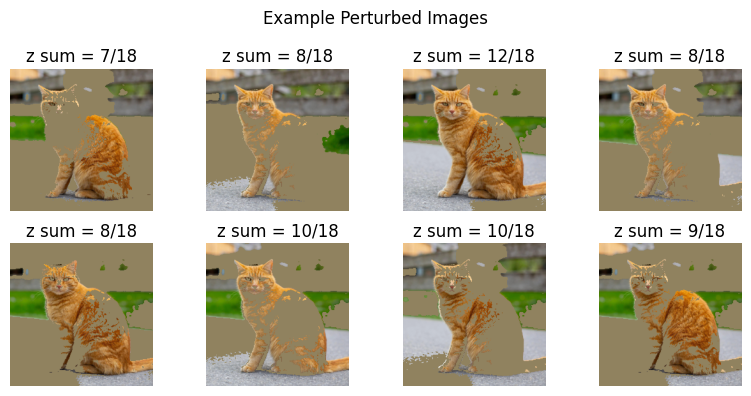

In [21]:
plt.figure(figsize=(8, 4))
for i in range(8):
    plt.subplot(2, 4, i + 1)
    plt.imshow(perturbed_images[i])
    plt.title("z sum = " + str(Z[i].sum()) + "/18")
    plt.axis("off")

plt.suptitle("Example Perturbed Images")
plt.tight_layout()
plt.show()

### Part 4 - Give Weights to Perturbed Images

In [ ]:
d = 18
sigma = 0.25 * np.sqrt(d)
all_one = np.ones(d)
epsilon = 1e-8
distances = []

for i in range(1000):
    z = Z[i]
    dot_product = np.dot(z, all_one)
    z_norm = np.linalg.norm(z)
    original_norm = np.linalg.norm(all_one)
    temp = 1 - (dot_product / (z_norm * original_norm + epsilon))
    distances.append(temp)
    
distances = np.array(distances)
weights = np.exp(-(distances ** 2) / (sigma ** 2))
print("Weights shape:", weights.shape)
print("\nFirst 10 weights:")
print(weights[:10])

Weights shape: (1000,)

First 10 weights:
[0.88167773 0.90595519 0.97051152 0.90595519 0.90595519 0.94399092
 0.94399092 0.92658026 0.92658026 0.94399092]


### Part 5 - Training Linear Model

In [39]:
cat_index = 282
def predict_class_prob(images, class_index, batch_size):
    probs_list = []
    model.eval()
    with torch.no_grad():
        for start in range(0, len(images), batch_size):
            batch_images = images[start:start + batch_size]
            batch_tensors = []

            for im in batch_images:
                pil_img = Image.fromarray(im.astype(np.uint8))
                batch_tensors.append(transform(pil_img))
            batch_tensors = torch.stack(batch_tensors).to(device)
            logits = model(batch_tensors)
            probs = F.softmax(logits, dim=1)
            selected_probs = probs[:, class_index].cpu().numpy()
            probs_list.extend(selected_probs)
    return np.array(probs_list)

y = predict_class_prob(perturbed_images, class_index=282, batch_size=32)
print("Output shape:", y.shape)
X = Z.astype(float)
linear_model = Lasso(alpha=0.01, fit_intercept=False, max_iter=10000)
linear_model.fit(X, y, sample_weight=weights)
coefs = linear_model.coef_
print("Coefficients shape:", coefs.shape)
print("LIME coefficients:")
print(coefs)

Output shape: (1000,)
Coefficients shape: (18,)
LIME coefficients:
[-0.          0.01085127  0.2098913  -0.          0.          0.
 -0.          0.08168315 -0.          0.00649372  0.00891208 -0.
  0.18960524  0.08528735 -0.          0.22982239  0.10426869 -0.        ]


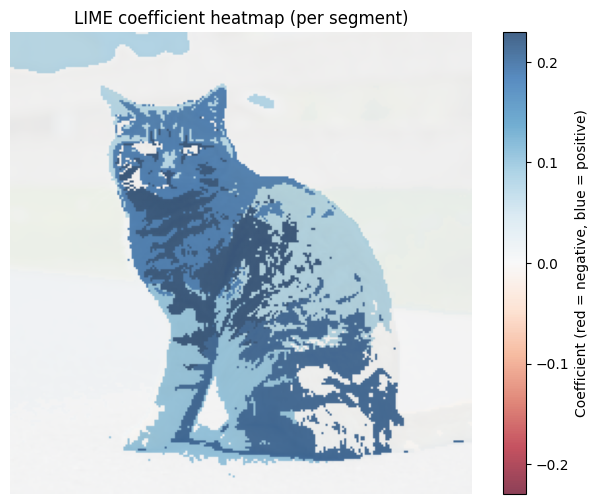

In [40]:
coef_map = np.zeros_like(segments, dtype=float)

for seg_id in range(len(coefs)):
    coef_map[segments == seg_id] = coefs[seg_id]

v = np.max(np.abs(coefs))
plt.figure(figsize=(8, 6))
plt.imshow(img_np, alpha=0.25)
plt.imshow(coef_map, cmap="RdBu", alpha=0.75, vmin=-v, vmax=v)
plt.title("LIME coefficient heatmap (per segment)")
plt.axis("off")
cbar = plt.colorbar()
cbar.set_label("Coefficient (red = negative, blue = positive)")
plt.show()

### Part 6 - Polar Bear

In [44]:
polar_path = "polarBear.png"
polar_img = load_image(polar_path)
polar_np = np.array(polar_img)
polar_original_prob = predict_class_prob(np.array([polar_np]), class_index=296, batch_size=1)[0]
print(f"Probability for polar bear class 296: {polar_original_prob*100:.2f}%")
polar_segments = kmeans_segments(polar_np, n_segments=18)
print(f"Number of segments: {len(np.unique(polar_segments))}")

Probability for polar bear class 296: 99.64%
Number of segments: 18


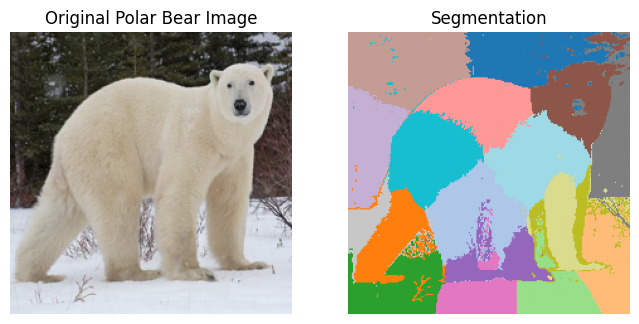

In [46]:
plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.imshow(polar_np)
plt.title("Original Polar Bear Image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(polar_segments, cmap="tab20")
plt.title("Segmentation")
plt.axis("off")
plt.show()

In [48]:
Z_polar = np.random.randint(0, 2, size=(1000, 18))
polar_perturbed_images = []
for i in range(1000):
    new_img = make_perturbed_image(polar_np, polar_segments, Z_polar[i])
    polar_perturbed_images.append(new_img)
polar_perturbed_images = np.array(polar_perturbed_images)
print("Perturbed images shape:", polar_perturbed_images.shape)

Perturbed images shape: (1000, 224, 224, 3)


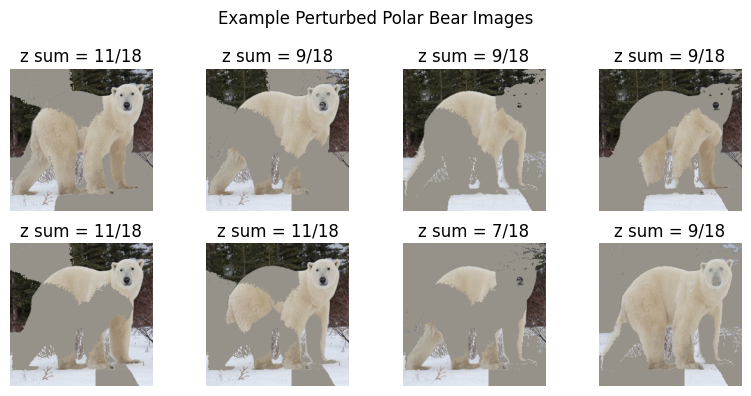

In [50]:
num_show = 8
plt.figure(figsize=(8, 4))
for i in range(num_show):
    plt.subplot(2, 4, i + 1)
    plt.imshow(polar_perturbed_images[i])
    plt.title("z sum = " + str(Z_polar[i].sum()) + "/18")
    plt.axis("off")
plt.suptitle("Example Perturbed Polar Bear Images")
plt.tight_layout()
plt.show()

In [51]:
distances_bear = []
for i in range(1000):
    z = Z_polar[i]
    dot_product = np.dot(z, all_one)
    z_norm = np.linalg.norm(z)
    original_norm = np.linalg.norm(all_one)
    temp = 1 - (dot_product / (z_norm * original_norm + epsilon))
    distances_bear.append(temp)
    
distances_bear = np.array(distances_bear)
weights_bear = np.exp(-(distances_bear ** 2) / (sigma ** 2))
print("Weights shape:", weights_bear.shape)
print("\nFirst 10 weights:")
print(weights_bear[:10])

Weights shape: (1000,)

First 10 weights:
[0.95853812 0.92658026 0.92658026 0.92658026 0.95853812 0.95853812
 0.88167773 0.92658026 0.97051152 0.81968815]


In [54]:
y_polar = predict_class_prob(polar_perturbed_images, class_index=296, batch_size=32)
print("Output shape:", y_polar.shape)
X_polar = Z_polar.astype(float)
polar_lime_model = Lasso(alpha=0.01, fit_intercept=False, max_iter=10000)
polar_lime_model.fit(X_polar, y_polar, sample_weight=weights_bear)
polar_coefs = polar_lime_model.coef_
print("Coefficients shape:", polar_coefs.shape)
print("LIME coefficients for polar bear image:")
print(polar_coefs)

Output shape: (1000,)
Coefficients shape: (18,)
LIME coefficients for polar bear image:
[0.09450123 0.07591295 0.06449167 0.03220816 0.03474939 0.00742813
 0.24282148 0.06855544 0.03696691 0.27157081 0.05673557 0.04373557
 0.08405141 0.05432533 0.09846837 0.11414693 0.12060894 0.0316713 ]


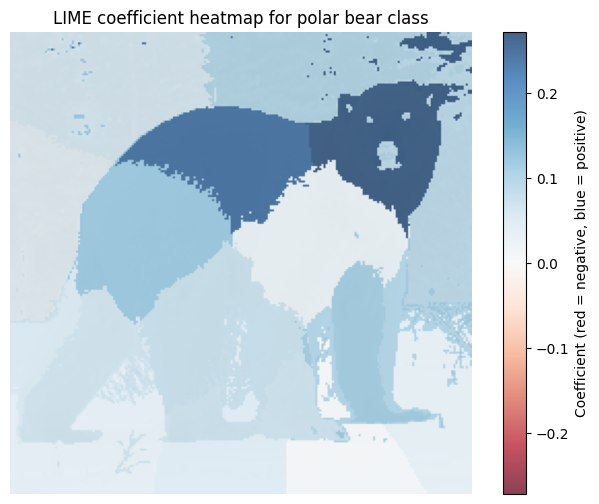

In [56]:
polar_coef_map = np.zeros_like(polar_segments, dtype=float)
for seg_id in range(len(polar_coefs)):
    polar_coef_map[polar_segments == seg_id] = polar_coefs[seg_id]
v = np.max(np.abs(polar_coefs))
plt.figure(figsize=(8, 6))
plt.imshow(polar_np, alpha=0.25)
plt.imshow(polar_coef_map, cmap="RdBu", alpha=0.75, vmin=-v, vmax=v)
plt.title("LIME coefficient heatmap for polar bear class")
plt.axis("off")
cbar = plt.colorbar()
cbar.set_label("Coefficient (red = negative, blue = positive)")
plt.show()